<a href="https://colab.research.google.com/github/Mayte-Otavalo/IA/blob/main/A_Analisis_Redes_Data_Mining_II_Viernes_Estudiantes_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de redes y Data Mining II
## Viernes · Versión para estudiantes

Estudiaremos fundamentos de grafos, algoritmos de recorrido y caminos mínimos, centralidades, conectividad y modelos de redes mediante ejemplos pequeños.

Al final trabajaremos con el dataset **Online Retail**: lo cargaremos para que desarrollen un EDA y analicen qué entidades y relaciones podrían representarse mediante teoría de grafos.


# Ruta de trabajo del viernes

1. Fundamentos y representaciones de grafos.
2. BFS, DFS, Dijkstra y Floyd–Warshall.
3. Centralidades, conectividad, modelos de redes y red de ego.
4. Carga de Online Retail, EDA y propuesta de representación como grafo.

Ejecuta los ejemplos en orden. En la última parte completa las celdas vacías con tu análisis y tus conclusiones.


## Objetivos de aprendizaje

- Representar grafos e interpretar dirección, pesos y distancias.
- Comparar algoritmos de recorrido y caminos mínimos.
- Interpretar métricas estructurales en ejemplos pequeños.
- Explorar Online Retail y justificar una posible representación de sus datos como grafo.


## 0. Preparación del entorno

Ejecuta la instalación y las importaciones antes de continuar. En Google Colab, la primera carga necesita conexión a Internet.

In [1]:
%pip install -q ucimlrepo networkx python-louvain scikit-learn matplotlib pandas scipy

### Interpretación
La instalación prepara el kernel actual. Si Colab solicita reiniciarlo tras una actualización, reinícielo y ejecute todo desde el comienzo.

## Preparación del entorno

En esta sección se importan las librerías necesarias para desarrollar el análisis.

Se utilizarán herramientas para:

- **Manipulación de datos:** NumPy y Pandas.
- **Visualización:** Matplotlib.
- **Análisis de redes:** NetworkX.
- **Detección de comunidades:** algoritmo de Louvain.
- **Machine Learning:** K-Means, PCA y StandardScaler.
- **Evaluación de agrupamientos:** Silhouette Score y Adjusted Rand Index.
- **Cálculo de similitud:** similitud coseno.
- **Obtención de datasets:** UCI Machine Learning Repository.

Finalmente, se establece una semilla aleatoria (`SEED = 42`) para garantizar la **reproducibilidad de los experimentos** y se configura el estilo general de las figuras.

In [2]:
import os
from pathlib import Path
from collections import deque
from itertools import combinations, islice

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import community.community_louvain as louvain

from IPython.display import display
from ucimlrepo import fetch_ucirepo
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Entorno preparado. NetworkX:', nx.__version__)

Entorno preparado. NetworkX: 3.7


# Parte I. Fundamentos de teoría de grafos

Un grafo se representa como **G = (V, E)**, donde `V` corresponde al conjunto de **nodos** y `E` al conjunto de **aristas** o relaciones entre ellos.

Las aristas pueden tener diferentes características:

- **Dirección:** indica el sentido de la relación, por ejemplo, A → B.
- **Peso:** representa la intensidad, frecuencia, costo o importancia de una relación.
- **Dirección y peso:** una arista puede combinar ambas características.

Un **camino** es una secuencia de nodos conectados mediante aristas. Un **ciclo** es un camino que comienza y termina en el mismo nodo. Dos nodos son **alcanzables** si existe un camino entre ellos. En un grafo no dirigido, se dice que el grafo es **conectado** cuando existe un camino entre cualquier par de nodos.

Algunos ejemplos de redes que pueden representarse mediante grafos son:

- Personas y relaciones de amistad.
- Ciudades y carreteras.
- Equipos y enlaces de comunicación.
- Clientes y productos.
- Usuarios e interacciones en sistemas de recomendación.

El significado de los pesos depende del problema analizado. Por ejemplo, un peso alto puede representar una **mayor similitud o frecuencia de interacción**, pero también podría representar un **mayor costo o distancia**.


## 1. Primer grafo: dirección y pesos

Un grafo representa entidades mediante **nodos** y relaciones mediante **aristas**. Compara el grafo no dirigido con el dirigido y observa cómo se almacenan sus pesos. Un peso puede representar costo, distancia o intensidad: su significado debe definirse para cada problema.

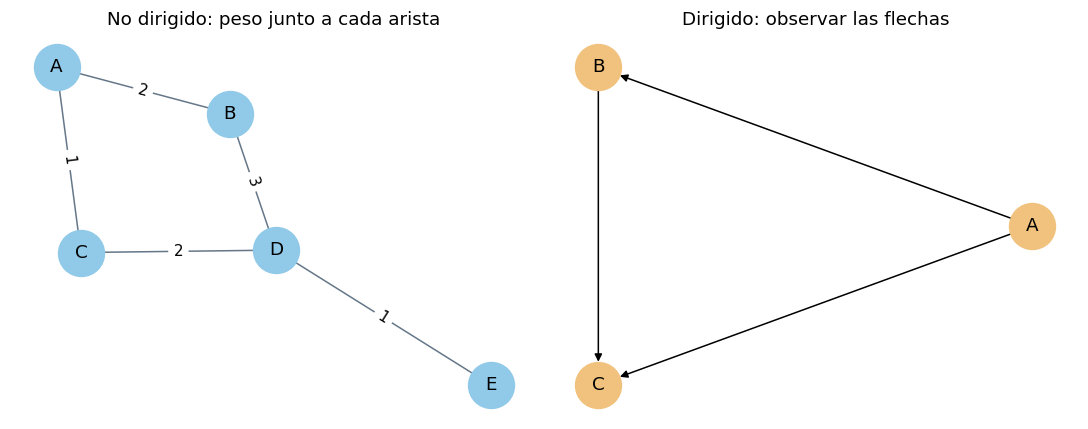

In [3]:
# Crear un grafo no dirigido y agregar aristas con sus respectivos pesos
G0 = nx.Graph()
G0.add_weighted_edges_from([('A','B',2),('A','C',1),('B','D',3),('C','D',2),('D','E',1)])

# Crear un grafo dirigido: las relaciones tienen un sentido específico
D0 = nx.DiGraph([('A','B'),('B','C'),('A','C')])

# Crear dos espacios de visualización lado a lado
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# Calcular la posición de los nodos del grafo no dirigido
pos0 = nx.spring_layout(G0, seed=SEED)

# Dibujar el grafo no dirigido y mostrar el peso de cada arista
nx.draw(G0, pos0, ax=axs[0], with_labels=True, node_color='#91c9e8',
        node_size=900, edge_color='#657788')
nx.draw_networkx_edge_labels(G0, pos0, edge_labels=nx.get_edge_attributes(G0,'weight'), ax=axs[0])

# Dibujar el grafo dirigido; las flechas indican el sentido de las relaciones
nx.draw(D0, nx.circular_layout(D0), ax=axs[1], with_labels=True,
        arrows=True, node_color='#f1c27d', node_size=900)

# Añadir títulos y mostrar la figura
axs[0].set_title('No dirigido: peso junto a cada arista')
axs[1].set_title('Dirigido: observar las flechas')
plt.tight_layout(); plt.show()

### Interpretación

El grafo de la izquierda contiene **5 nodos y 5 aristas**. Las conexiones no tienen dirección y cada arista posee un **peso**. Por ejemplo, el nodo `D` está conectado con `E`, y la arista `B–D` tiene un peso de **3**.

En el grafo de la derecha, las aristas son **dirigidas** y se interpretan como pares ordenados. Por ejemplo, `A → B` indica una relación desde `A` hacia `B`, pero no necesariamente desde `B` hacia `A`.

Es importante recordar que un peso como el valor **3** de `B–D` no representa automáticamente una distancia. Su significado depende del problema: podría representar frecuencia, costo, similitud, cantidad de interacciones u otra medida.

## 2. Tres representaciones del mismo grafo

Representamos el mismo grafo como **lista de adyacencia**, **matriz de adyacencia** y **lista de aristas**. Compara cómo se recuperan los vecinos y los pesos en cada representación. La matriz de un grafo no dirigido es simétrica.

In [4]:
# Crear la lista de adyacencia: para cada nodo se muestran sus vecinos
lista = pd.DataFrame({'Nodo': sorted(G0),
                      'Vecinos': [', '.join(sorted(G0.neighbors(n))) for n in sorted(G0)]})

# Crear la matriz de adyacencia sin considerar los pesos
ady = nx.to_pandas_adjacency(G0, nodelist=sorted(G0), weight=None, dtype=int)

# Obtener las aristas y construir manualmente la matriz de incidencia
aristas0 = sorted(tuple(sorted(e)) for e in G0.edges())
inc = pd.DataFrame(0, index=sorted(G0),
                   columns=[f'{u}–{v}' for u,v in aristas0], dtype=int)

# Marcar con 1 los dos nodos que participan en cada arista
for u,v in aristas0:
    inc.loc[[u,v], f'{u}–{v}'] = 1

# Mostrar las tres representaciones
print('Lista de adyacencia'); display(lista)
print('Matriz de adyacencia (fila=nodo origen; columna=vecino)'); display(ady)
print('Matriz de incidencia (fila=nodo; columna=arista)'); display(inc)

# Verificar propiedades esperadas de un grafo no dirigido
print('¿Simétrica?', np.array_equal(ady.to_numpy(), ady.to_numpy().T),
      '| Unos por columna de incidencia:', inc.sum(axis=0).unique().tolist())

Lista de adyacencia


,Nodo,Vecinos
0,A,"B, C"
1,B,"A, D"
2,C,"A, D"
3,D,"B, C, E"
4,E,D


Matriz de adyacencia (fila=nodo origen; columna=vecino)


,A,B,C,D,E
A,0,1,1,0,0
B,1,0,0,1,0
C,1,0,0,1,0
D,0,1,1,0,1
E,0,0,0,1,0


Matriz de incidencia (fila=nodo; columna=arista)


,A–B,A–C,B–D,C–D,D–E
A,1,1,0,0,0
B,1,0,1,0,0
C,0,1,0,1,0
D,0,0,1,1,1
E,0,0,0,0,1


¿Simétrica? True | Unos por columna de incidencia: [2]


### Interpretación

Para este grafo no dirigido, la **matriz de adyacencia es simétrica**, porque si `A` está conectado con `B`, entonces `B` también está conectado con `A`.

La **matriz de incidencia** tiene una columna por cada una de las 5 aristas, y en cada columna aparecen exactamente **dos valores iguales a 1**, correspondientes a los dos nodos que forman esa arista.

La **lista de adyacencia** es eficiente para grafos con pocas conexiones, ya que evita almacenar gran cantidad de ceros. En cambio, la **matriz de adyacencia** facilita consultar rápidamente si dos nodos están conectados, aunque requiere un espacio proporcional a **O(|V|²)**.

La **matriz de incidencia**, en formato denso, requiere aproximadamente **O(|V|·|E|)** y resulta útil para analizar la relación entre nodos y aristas. En grafos dirigidos también puede utilizarse una incidencia orientada, empleando valores como **−1** para el nodo de origen y **+1** para el nodo de destino.

## 3. Tipos de grafos

Compara grafos completos, cíclicos, acíclicos y desconectados. Identifica qué cambia en sus conexiones, ciclos y componentes; estas propiedades pueden coexistir y no constituyen categorías excluyentes.

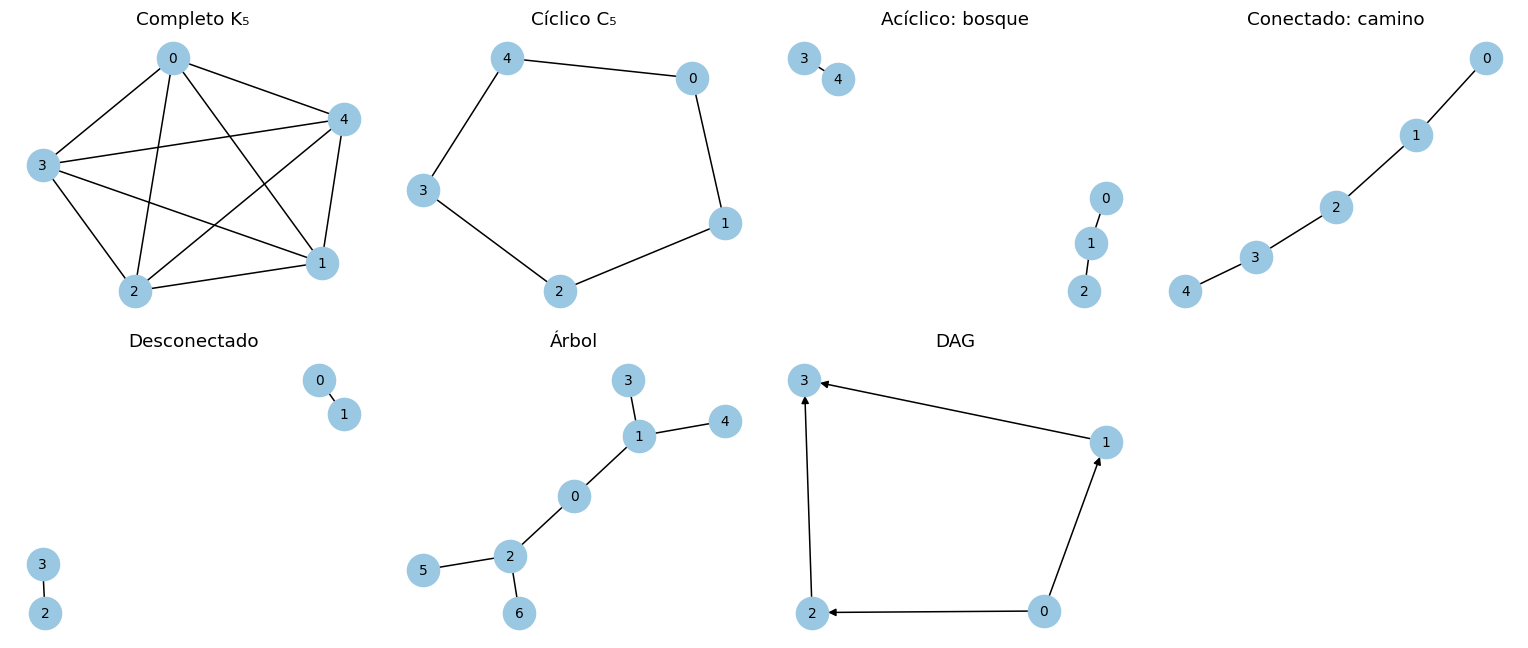

In [5]:
# Crear ejemplos de diferentes tipos de grafos
ejemplos = [
    ('Completo K₅', nx.complete_graph(5)), ('Cíclico C₅', nx.cycle_graph(5)),
    ('Acíclico: bosque', nx.Graph([(0,1),(1,2),(3,4)])),
    ('Conectado: camino', nx.path_graph(5)),
    ('Desconectado', nx.Graph([(0,1),(2,3)])),
    ('Árbol', nx.balanced_tree(2,2)),
    ('DAG', nx.DiGraph([(0,1),(0,2),(1,3),(2,3)]))
]

# Crear una cuadrícula para visualizar los ejemplos
fig, axs = plt.subplots(2, 4, figsize=(14, 6))

# Dibujar cada grafo; mostrar flechas únicamente en grafos dirigidos
for ax,(nombre,g) in zip(axs.flat, ejemplos):
    nx.draw(g, nx.spring_layout(g, seed=SEED), ax=ax, with_labels=True,
            arrows=g.is_directed(), node_size=440, node_color='#9ac7e1', font_size=9)
    ax.set_title(nombre)

# Ocultar el espacio sobrante y mostrar la figura
axs.flat[-1].axis('off'); plt.tight_layout(); plt.show()

### Interpretación

El grafo **completo `K₅`** conecta cada nodo con todos los demás, por lo que contiene todas las aristas posibles entre sus 5 nodos.

El grafo **cíclico `C₅`** contiene un camino cerrado que permite regresar al nodo inicial.

El **bosque** no contiene ciclos, pero está formado por más de un componente y, por tanto, es desconectado.

El **camino** es conectado y acíclico, por lo que también cumple la definición de árbol.

El ejemplo denominado **árbol** muestra otra estructura conectada sin ciclos, pero con ramificaciones.

El **DAG** es un grafo dirigido sin ciclos dirigidos. Sin embargo, si ignoramos la dirección de sus aristas, su estructura forma un ciclo con forma de rombo. Esto muestra que la presencia de ciclos depende también de si se considera o no la dirección de las relaciones.

# Parte II. Algoritmos fundamentales

## 4. BFS: cola y niveles

**BFS** utiliza una cola y explora el grafo por niveles desde un nodo de origen. En una red sin pesos, los niveles corresponden al mínimo número de saltos desde ese origen. Observa el recorrido y la estructura de niveles.

,Orden,Nodo,Nivel
0,1,A,0
1,2,B,1
2,3,C,1
3,4,D,2
4,5,E,2
5,6,F,2


NetworkX (aristas BFS): [('A', 'B'), ('A', 'C'), ('B', 'D'), ('B', 'E'), ('C', 'F')]
Camino mínimo A→F: ['A', 'C', 'F']


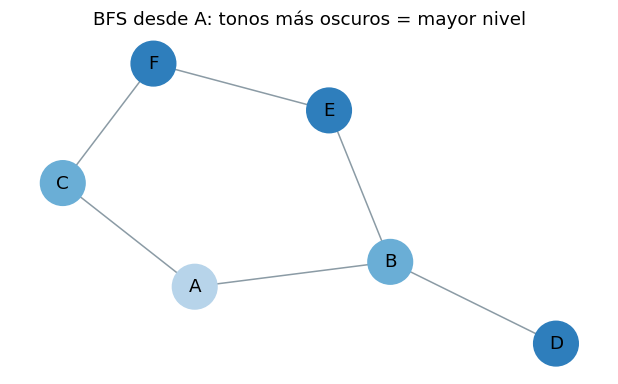

In [6]:
# Crear un grafo sencillo para demostrar el recorrido BFS
G_busqueda = nx.Graph([('A','B'),('A','C'),('B','D'),('B','E'),('C','F'),('E','F')])

# Implementar BFS utilizando una cola y registrar el nivel de cada nodo
def bfs_niveles(grafo, origen):
    cola = deque([origen]); visitados = {origen}; nivel = {origen: 0}; orden = []
    while cola:
        actual = cola.popleft(); orden.append(actual)
        for vecino in sorted(grafo.neighbors(actual)):
            if vecino not in visitados:
                visitados.add(vecino); nivel[vecino] = nivel[actual] + 1
                cola.append(vecino)
    return orden, nivel

# Ejecutar BFS desde el nodo A y mostrar orden y niveles
orden_bfs, niveles = bfs_niveles(G_busqueda, 'A')
display(pd.DataFrame({'Orden': range(1, len(orden_bfs)+1), 'Nodo': orden_bfs,
                      'Nivel': [niveles[x] for x in orden_bfs]}))

# Comparar con NetworkX y obtener un camino mínimo entre A y F
print('NetworkX (aristas BFS):', list(nx.bfs_edges(G_busqueda, 'A', sort_neighbors=sorted)))
print('Camino mínimo A→F:', nx.shortest_path(G_busqueda,'A','F'))

# Visualizar los niveles del recorrido BFS
pos_busqueda = nx.spring_layout(G_busqueda, seed=SEED)
fig,ax=plt.subplots(figsize=(7,4))
nx.draw(G_busqueda, pos_busqueda, ax=ax, with_labels=True, node_size=850,
        node_color=[plt.cm.Blues(0.3+0.2*niveles[x]) for x in G_busqueda],
        edge_color='#8b9ba5')
ax.set_title('BFS desde A: tonos más oscuros = mayor nivel'); plt.show()

### Interpretación

El recorrido comienza en `A`, ubicado en el **nivel 0**. Sus vecinos directos, `B` y `C`, se encuentran en el **nivel 1**, mientras que `D`, `E` y `F` aparecen en el **nivel 2**.

BFS procesa los nodos utilizando una cola, por lo que primero explora todos los nodos de un nivel antes de continuar con el siguiente. El orden entre nodos pertenecientes al mismo nivel puede variar según el criterio utilizado para ordenar los vecinos.

La implementación de **NetworkX** produce un árbol BFS equivalente al recorrido realizado manualmente.

Además, como el grafo no tiene pesos, BFS permite encontrar caminos con el menor número de aristas. En este ejemplo, el camino mínimo entre `A` y `F` es:

**A → C → F**

Este camino utiliza **2 aristas**.

## 5. DFS y comparación con BFS

**DFS** utiliza una pila y avanza por una rama antes de retroceder. Compara su orden de visita con BFS. El orden depende de cómo se procesan los vecinos; DFS no garantiza el camino con menos saltos.

In [7]:
# Implementar DFS utilizando una pila
def dfs_pila(grafo, origen):
    pila=[origen]; visitados=set(); orden=[]
    while pila:
        actual=pila.pop()
        if actual in visitados: continue
        visitados.add(actual); orden.append(actual)

        # Agregar vecinos no visitados a la pila
        pila.extend(reversed(sorted(v for v in grafo.neighbors(actual)
                                   if v not in visitados)))
    return orden

# Ejecutar DFS desde A y comparar el orden con BFS
orden_dfs=dfs_pila(G_busqueda,'A')
display(pd.DataFrame({'Paso': range(1,len(orden_bfs)+1), 'BFS': orden_bfs,
                      'DFS': orden_dfs}))

# Resumir las principales diferencias entre BFS y DFS
display(pd.DataFrame([
    ['BFS','por niveles','cola','alcanzabilidad y mínimos saltos'],
    ['DFS','profundiza y retrocede','pila o recursión','exploración, ciclos y componentes']],
    columns=['Algoritmo','Estrategia','Estructura','Uso típico']))

# Comparar el recorrido DFS con la implementación de NetworkX
print('NetworkX (DFS preorden):',
      list(nx.dfs_preorder_nodes(G_busqueda,'A',sort_neighbors=sorted)))

,Paso,BFS,DFS
0,1,A,A
1,2,B,B
2,3,C,D
3,4,D,E
4,5,E,F
5,6,F,C


,Algoritmo,Estrategia,Estructura,Uso típico
0,BFS,por niveles,cola,alcanzabilidad y mínimos saltos
1,DFS,profundiza y retrocede,pila o recursión,"exploración, ciclos y componentes"


NetworkX (DFS preorden): ['A', 'B', 'D', 'E', 'F', 'C']


### Interpretación

Ambos algoritmos visitan los **seis nodos** del grafo, pero lo hacen siguiendo estrategias diferentes.

Con los vecinos ordenados alfabéticamente, **BFS** comienza en `A`, visita primero `B` y `C`, y después continúa con los nodos de los siguientes niveles.

En cambio, **DFS** comienza en `A` y profundiza por una rama, por ejemplo:

**A → B → D**

Cuando ya no puede continuar por esa rama, retrocede hasta encontrar otro vecino que todavía no haya sido visitado.

La diferencia principal es que **BFS utiliza una cola y recorre por niveles**, mientras que **DFS utiliza una pila y prioriza la profundidad**.

DFS también es útil en tareas como la detección de ciclos, exploración de componentes y, en grafos dirigidos acíclicos (DAG), como base para realizar un ordenamiento topológico.

## 6. Dijkstra: minimizar costo

**Dijkstra** minimiza la suma de costos de las aristas cuando los pesos son no negativos. Compara la conexión directa con una ruta de varios saltos: menos aristas no implica menor costo.

### Antes de ejecutar: ¿qué esperas que ocurra?

**Dijkstra**

> ¿El camino con menos saltos necesariamente tendrá menor costo?

Ruta mínima por saltos: ['A', 'D'] | saltos: 1
Ruta de Dijkstra: ['A', 'B', 'C', 'D'] | costo: 5


,Costo_desde_A
A,0
B,1
C,3
D,5


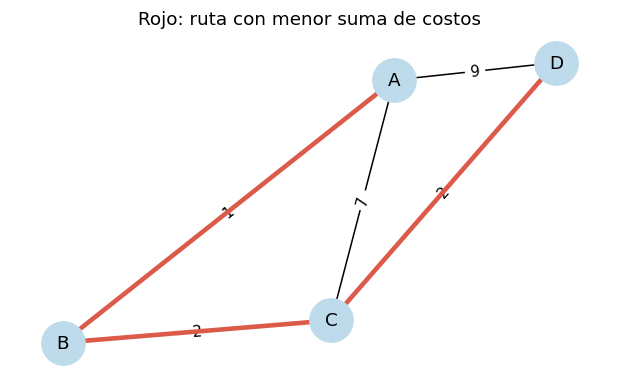

In [8]:
# Crear un grafo ponderado donde los pesos representan costos
G_costo=nx.Graph()
G_costo.add_weighted_edges_from([('A','D',9),('A','B',1),('B','C',2),('C','D',2),('A','C',7)])

# Comparar la ruta con menos saltos frente a la ruta con menor costo
saltos=nx.shortest_path(G_costo,'A','D')
ruta_costo=nx.shortest_path(G_costo,'A','D',weight='weight',method='dijkstra')

print('Ruta mínima por saltos:', saltos, '| saltos:', len(saltos)-1)
print('Ruta de Dijkstra:', ruta_costo,
      '| costo:', nx.shortest_path_length(G_costo,'A','D',weight='weight'))

# Calcular el costo mínimo desde A hacia todos los nodos
display(pd.DataFrame.from_dict(nx.single_source_dijkstra_path_length(G_costo,'A'),
                               orient='index', columns=['Costo_desde_A']).sort_index())

# Visualizar el grafo y resaltar la ruta de menor costo
pos_costo=nx.spring_layout(G_costo,seed=SEED)
fig,ax=plt.subplots(figsize=(7,4))
nx.draw(G_costo,pos_costo,ax=ax,with_labels=True,node_size=800,node_color='#bddbeb')
nx.draw_networkx_edge_labels(G_costo,pos_costo,edge_labels=nx.get_edge_attributes(G_costo,'weight'),ax=ax)
nx.draw_networkx_edges(G_costo,pos_costo,edgelist=list(zip(ruta_costo[:-1],ruta_costo[1:])),
                       ax=ax,edge_color='#db5a49',width=3)

ax.set_title('Rojo: ruta con menor suma de costos'); plt.show()

### Interpretación

La conexión directa `A–D` utiliza solamente **1 salto**, pero tiene un costo de **9**.

Dijkstra encuentra la ruta:

**A → B → C → D**

Su costo total es:

**1 + 2 + 2 = 5**

Aunque esta ruta utiliza **3 saltos**, su costo acumulado es menor que el de la conexión directa.

Esto muestra la diferencia entre buscar el camino con **menos aristas** y buscar el camino con **menor costo total**.

También es importante interpretar correctamente los pesos. Dijkstra supone que valores pequeños representan conexiones más convenientes. Si el peso representa una **similitud**, donde un valor alto significa una relación más fuerte, no debería utilizarse directamente como costo; primero debe transformarse en una medida de distancia o costo compatible con el algoritmo.

## 7. Floyd–Warshall: caminos mínimos entre todos los pares

**Floyd–Warshall** calcula caminos mínimos entre todos los pares de nodos. Cada posición de la matriz muestra el costo mínimo entre origen y destino; la diagonal representa el costo de llegar de un nodo a sí mismo. En este ejemplo usamos el mismo grafo ponderado de Dijkstra.

In [9]:
# Ordenar los nodos para mostrar la matriz de forma consistente
nodos_costo=sorted(G_costo)

# Calcular los costos mínimos entre todos los pares de nodos
fw=dict(nx.floyd_warshall(G_costo,weight='weight'))
display(pd.DataFrame(fw).loc[nodos_costo,nodos_costo])

# Comparar el propósito de BFS, Dijkstra y Floyd–Warshall
display(pd.DataFrame([
    ['BFS','un origen / una ruta','grafo no ponderado','mínimos saltos'],
    ['Dijkstra','un origen / una ruta','costos no negativos','mínima suma de costos'],
    ['Floyd–Warshall','todos los pares','grafo pequeño/mediano','matriz de costos mínimos']],
    columns=['Algoritmo','Alcance','Condición','Salida principal']))

,A,B,C,D
A,0,1,3,5
B,1,0,2,4
C,3,2,0,2
D,5,4,2,0


,Algoritmo,Alcance,Condición,Salida principal
0,BFS,un origen / una ruta,grafo no ponderado,mínimos saltos
1,Dijkstra,un origen / una ruta,costos no negativos,mínima suma de costos
2,Floyd–Warshall,todos los pares,grafo pequeño/mediano,matriz de costos mínimos


### Interpretación

La matriz muestra el **costo mínimo para viajar entre cada par de nodos** del grafo.

Por ejemplo, aunque existe una conexión directa entre `A` y `D` con costo `9`, Floyd–Warshall encuentra que la ruta:

**A → B → C → D**

tiene un costo menor:

**1 + 2 + 2 = 5**

La diagonal principal contiene valores iguales a **0**, porque el costo de ir desde un nodo hacia sí mismo es cero.

Como `G_costo` es un grafo no dirigido, la matriz de distancias es **simétrica**: el costo mínimo de `A` hacia `D` es el mismo que de `D` hacia `A`.

Floyd–Warshall resulta útil cuando necesitamos conocer las distancias mínimas entre **todos los pares de nodos**, pero su costo computacional **O(|V|³)** puede ser elevado para redes grandes.

Si el grafo estuviera desconectado, los pares de nodos entre los que no existe ningún camino aparecerían con una distancia **infinita (`inf`)**.

# Parte III. Graph Analytics con ejemplos comprensibles

## 8. Cuatro medidas de centralidad

Compara **Degree**, **Closeness**, **Betweenness** y **Eigenvector Centrality**. Describen, respectivamente, conexiones directas, cercanía por caminos, participación en caminos mínimos y conexión con nodos centrales. No existe una única medida de importancia válida para toda pregunta.

### Antes de ejecutar: ¿qué esperas que ocurra?

**Centralidades en un ejemplo pequeño**

> ¿El nodo con más vecinos necesariamente es el principal puente de la red?

,Nodo,Degree,Closeness,Betweenness,Eigenvector
2,Carlos,1.000,1.00,0.667,0.612
0,Ana,0.667,0.75,0.000,0.523
1,María,0.667,0.75,0.000,0.523
3,David,0.333,0.60,0.000,0.282


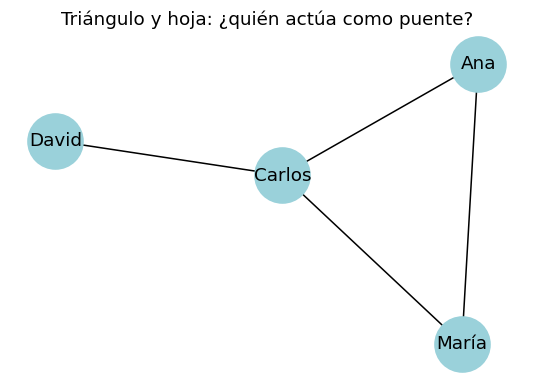

In [10]:
# Crear una pequeña red social: un triángulo conectado con un nodo externo
G_social=nx.Graph([('Ana','María'),('Ana','Carlos'),('María','Carlos'),('Carlos','David')])

# Calcular cuatro medidas de centralidad para cada nodo
def tabla_centralidad(g):
    grado=nx.degree_centrality(g); cerca=nx.closeness_centrality(g)
    puente=nx.betweenness_centrality(g)
    vector=nx.eigenvector_centrality(g,max_iter=2000) if g.number_of_edges() else dict.fromkeys(g,0.)
    return pd.DataFrame({'Nodo':list(g),'Degree':[grado[x] for x in g],
                         'Closeness':[cerca[x] for x in g],
                         'Betweenness':[puente[x] for x in g],
                         'Eigenvector':[vector[x] for x in g]})

# Mostrar los resultados ordenados por intermediación
display(tabla_centralidad(G_social).sort_values('Betweenness',ascending=False).round(3))

# Visualizar la estructura de la red
fig,ax=plt.subplots(figsize=(6,4))
nx.draw(G_social,nx.spring_layout(G_social,seed=SEED),ax=ax,with_labels=True,
        node_color='#9ad1da',node_size=1300)
ax.set_title('Triángulo y hoja: ¿quién actúa como puente?'); plt.show()

### Interpretación

`Carlos` ocupa una posición especialmente importante en esta pequeña red. Tiene conexión directa con **Ana, María y David**, por lo que presenta una alta **Degree Centrality**.

Además, se encuentra a poca distancia del resto de los nodos, lo que favorece su **Closeness Centrality**.

Su papel resulta especialmente evidente en **Betweenness Centrality**: cualquier camino desde `David` hacia `Ana` o `María` debe pasar por `Carlos`. Por esta razón, actúa como un **puente** entre `David` y el resto de la red.

Las cuatro medidas pueden interpretarse de forma sencilla como:

- **Degree:** ¿con cuántos nodos estoy conectado directamente?
- **Closeness:** ¿qué tan cerca estoy del resto de la red?
- **Betweenness:** ¿con qué frecuencia aparezco como puente entre otros nodos?
- **Eigenvector:** ¿estoy conectado con nodos que también están bien conectados?

Es importante recordar que una centralidad alta describe una **posición estructural dentro del grafo**, pero no demuestra por sí sola influencia, liderazgo o importancia real fuera de la red analizada.

## 9. Conectividad de nodos y componentes

Un **componente conectado** reúne nodos entre los que existe algún camino. La conectividad de nodos expresa cuántos nodos deben retirarse como mínimo para desconectar el grafo, bajo la definición utilizada por NetworkX. Compara un camino, un ciclo y una red con dos componentes.

### Antes de ejecutar: ¿qué esperas que ocurra?

**Conectividad y distancias**

> ¿Qué ocurre con el diámetro si la red no es completamente conexa? ¿Sobre qué componente tendría sentido calcularlo?

,Grafo,Componentes,Conectividad_de_nodos
0,Camino,1,1
1,Ciclo,1,2
2,Dos componentes,2,0


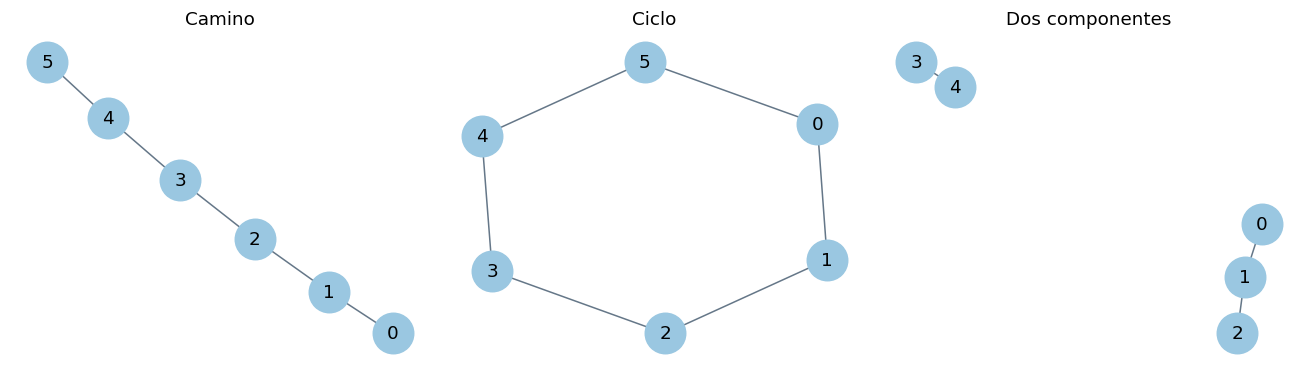

In [11]:
# Crear tres grafos con diferentes niveles de conectividad
grafos_con=[('Camino',nx.path_graph(6)),('Ciclo',nx.cycle_graph(6)),
            ('Dos componentes',nx.Graph([(0,1),(1,2),(3,4)]))]

# Calcular número de componentes y conectividad de nodos
display(pd.DataFrame([{'Grafo':nombre,
    'Componentes':nx.number_connected_components(g),
    'Conectividad_de_nodos':nx.node_connectivity(g)} for nombre,g in grafos_con]))

# Visualizar los tres grafos para comparar su estructura
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))

for ax, (nombre, g) in zip(axs, grafos_con):
    nx.draw(g, nx.spring_layout(g, seed=SEED), ax=ax, with_labels=True,
            node_size=700, node_color='#9ac7e1', edge_color='#657788')
    ax.set_title(nombre)

plt.tight_layout(); plt.show()

### Interpretación

El **camino** tiene una conectividad de nodos igual a **1**. Esto significa que basta eliminar un nodo intermedio adecuado para dividir la red en dos partes.

El **ciclo** tiene conectividad igual a **2**. Como existen rutas alternativas entre los nodos, eliminar un solo nodo no es suficiente para desconectar la red.

El tercer grafo ya se encuentra dividido en **2 componentes**, por lo que su conectividad global es **0**.

Es importante distinguir estos conceptos:

- **Número de componentes:** indica cuántos grupos desconectados existen actualmente.
- **Conectividad de nodos:** indica cuántos nodos deben eliminarse como mínimo para desconectar una red conectada.
- **Grado de un nodo:** indica únicamente cuántos vecinos directos tiene ese nodo.

Por tanto, una red con mayor conectividad de nodos presenta mayor **redundancia estructural** frente a la pérdida de nodos. Es decir la red tiene más caminos alternativos para mantenerse conectada si algunos nodos desaparecen.

## 10. Caminos, distancia promedio y diámetro

La **distancia** cuenta las aristas de un camino mínimo; la **distancia promedio** resume esas distancias entre pares y el **diámetro** es su máximo. En esta sección contamos saltos, sin pesos. Las definiciones habituales de distancia promedio y diámetro requieren un grafo conectado.

Camino A→F: ['A', 'C', 'F'] | longitud: 2
Distancia media: 1.733 | diámetro: 3
Para una red desconectada mediremos estas dos últimas cantidades en su componente principal.


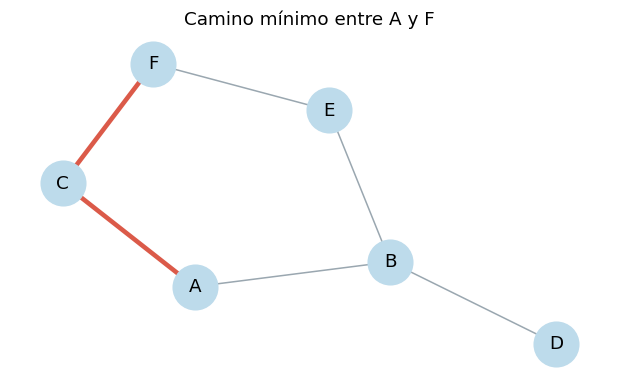

In [12]:
# Encontrar el camino mínimo entre A y F
ruta_af=nx.shortest_path(G_busqueda,'A','F')

print('Camino A→F:',ruta_af,
      '| longitud:',nx.shortest_path_length(G_busqueda,'A','F'))

# Calcular medidas globales de distancia
print('Distancia media:',round(nx.average_shortest_path_length(G_busqueda),3),
      '| diámetro:',nx.diameter(G_busqueda))

print('Para una red desconectada mediremos estas dos últimas cantidades en su componente principal.')

# Visualizar y resaltar el camino mínimo A→F
pos=nx.spring_layout(G_busqueda,seed=SEED)
fig,ax=plt.subplots(figsize=(7,4))

nx.draw(G_busqueda,pos,ax=ax,with_labels=True,
        node_size=850,node_color='#bddbeb',edge_color='#9aa7b0')

nx.draw_networkx_edges(G_busqueda,pos,
    edgelist=list(zip(ruta_af[:-1],ruta_af[1:])),
    ax=ax,edge_color='#db5a49',width=3)

ax.set_title('Camino mínimo entre A y F'); plt.show()

### Interpretación

El camino mínimo entre `A` y `F` es:

**A → C → F**

y utiliza **2 aristas o saltos**.

La **distancia promedio** resume cuántos saltos se necesitan, en promedio, para desplazarse entre los diferentes pares de nodos de la red.

El **diámetro** corresponde a la mayor de todas las distancias mínimas. Por tanto, representa el número máximo de saltos necesarios para conectar dos nodos utilizando siempre el camino más corto disponible.

Estas métricas pueden calcularse directamente porque `G_busqueda` es un grafo conectado. Si una red estuviera desconectada, no existiría un camino entre todos los pares de nodos; en ese caso, normalmente se analizan estas métricas sobre el **componente conectado principal**, indicando siempre cuántos nodos contiene.

## 11. Modelos de generación: ER, BA y WS

Compara tres modelos de generación de redes:

- **ER:** conexiones aleatorias entre pares.
- **BA:** crecimiento con preferencia por nodos que ya tienen más enlaces.
- **WS:** modificación de una red regular para introducir conexiones de largo alcance.

Observa diferencias en grado, clustering y distancias. Una similitud visual con estos ejemplos no identifica por sí sola el mecanismo que originó una red real.

,Modelo,Nodos,Aristas,Densidad,Clustering,Componente_principal,Distancia_media_LCC,Grado_máximo
0,Erdős–Rényi,40,77,0.099,0.116,40,2.832,8
1,Barabási–Albert,40,76,0.097,0.292,40,2.369,21
2,Watts–Strogatz,40,80,0.103,0.297,40,3.192,6


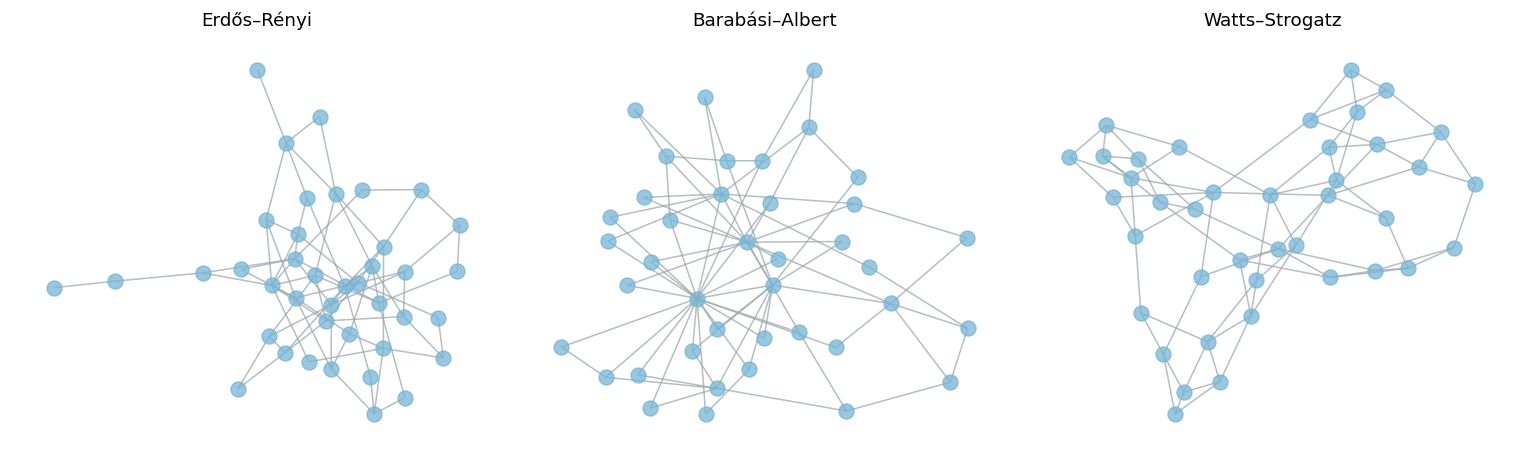

In [13]:
# Generar tres modelos de redes con tamaño similar
modelos={
    'Erdős–Rényi':nx.erdos_renyi_graph(40,4/39,seed=SEED),
    'Barabási–Albert':nx.barabasi_albert_graph(40,2,seed=SEED),
    'Watts–Strogatz':nx.watts_strogatz_graph(40,4,0.15,seed=SEED)}

# Calcular métricas descriptivas de cada red
filas_modelos=[]
for nombre,g in modelos.items():
    lcc=g.subgraph(max(nx.connected_components(g),key=len))
    filas_modelos.append({'Modelo':nombre,'Nodos':len(g),'Aristas':g.number_of_edges(),
        'Densidad':nx.density(g),'Clustering':nx.average_clustering(g),
        'Componente_principal':len(lcc),'Distancia_media_LCC':nx.average_shortest_path_length(lcc),
        'Grado_máximo':max(dict(g.degree()).values())})

# Mostrar la comparación tabular
display(pd.DataFrame(filas_modelos).round(3))

# Visualizar las tres redes generadas
fig,axs=plt.subplots(1,3,figsize=(14,4.3))
for ax,(nombre,g) in zip(axs,modelos.items()):
    nx.draw(g,nx.spring_layout(g,seed=SEED),ax=ax,with_labels=False,
            node_size=95,node_color='#77b5d6',edge_color='#9ca8ad',alpha=.75)
    ax.set_title(nombre)

plt.tight_layout(); plt.show()

### Interpretación

Los tres modelos generan redes con un número parecido de nodos, pero con estructuras diferentes.

- **Erdős–Rényi (ER)** conecta pares de nodos al azar. Por eso su estructura suele verse más irregular y sin una organización evidente.
- **Barabási–Albert (BA)** incorpora nodos nuevos con preferencia por nodos que ya tienen muchas conexiones. Esto puede producir **hubs**, es decir, nodos con grado mucho mayor que el resto.
- **Watts–Strogatz (WS)** comienza con una red local regular y luego reconecta algunas aristas. Esto suele favorecer un **clustering** relativamente alto junto con caminos cortos.

En la tabla, la columna **Clustering** resume el nivel de agrupamiento local, mientras que **Grado_máximo** ayuda a identificar si aparecen nodos muy conectados.

La columna **Componente_principal** indica cuántos nodos pertenecen al componente conectado más grande, y **Distancia_media_LCC** se calcula únicamente sobre ese componente principal.

Es importante interpretar estos resultados como un **ejemplo ilustrativo**: una sola realización de cada modelo no permite generalizar completamente su comportamiento teórico.

## 12. Ego Network

Una **ego network** contiene un nodo central (**ego**), sus vecinos (**alters**) y las aristas entre ellos. Extraemos la red de radio 1 de Carlos para observar su entorno y la cohesión entre sus vecinos.

Ego: Carlos | Alters: ['Ana', 'David', 'María'] | Aristas entre alters: [('Ana', 'María')]


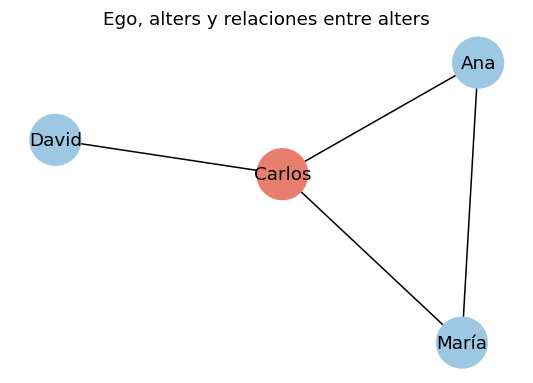

In [14]:
# Extraer la ego network de Carlos con radio 1
ego_peq=nx.ego_graph(G_social,'Carlos',radius=1)

# Identificar los alters (vecinos directos del ego)
alters=sorted(set(ego_peq)-{'Carlos'})

# Mostrar información básica de la ego network
print('Ego: Carlos | Alters:',alters,'| Aristas entre alters:',
      [e for e in ego_peq.edges() if 'Carlos' not in e])

# Visualizar la red de ego, destacando al nodo central
fig,ax=plt.subplots(figsize=(6,4))
nx.draw(ego_peq,nx.spring_layout(ego_peq,seed=SEED),ax=ax,with_labels=True,
        node_size=1100,node_color=['#e97e6e' if n=='Carlos' else '#9dc8e3' for n in ego_peq])

ax.set_title('Ego, alters y relaciones entre alters'); plt.show()

### Interpretación

En esta red de ego, **Carlos** es el nodo central o **ego**.

Sus vecinos directos, llamados **alters**, son:

- `Ana`
- `María`
- `David`

Además de las conexiones entre `Carlos` y cada uno de sus alters, la ego network conserva las relaciones que ya existían entre los alters en la red original. En este caso, `Ana` y `María` también están conectadas entre sí.

Por tanto, esta subred permite observar no solo quiénes están directamente relacionados con `Carlos`, sino también si esos vecinos forman un grupo más cohesionado o si dependen del ego para estar conectados.

Una ego network de radio 1 muestra la **vecindad inmediata** del nodo seleccionado y resulta útil para estudiar su contexto local dentro de la red.

# Parte IV Introducción al dataset Online Retail

Usaremos **Online Retail**, un conjunto de transacciones comerciales. El objetivo de esta actividad es conocer los datos y proponer cómo analizarlos con teoría de grafos.

**Fuente:** Daqing Chen, UCI Machine Learning Repository, 2015. DOI [10.24432/C5BW33](https://doi.org/10.24432/C5BW33). Licencia CC BY 4.0. [Ficha del dataset](https://archive.ics.uci.edu/dataset/352/online+retail).

Ejecuta la carga. Las siguientes celdas están vacías para que desarrolles el EDA y expliques tus decisiones.


## Carga del dataset

El dataset quedará disponible en el DataFrame `df_raw`. Conserva los datos originales y usa una copia si decides aplicar cambios. La descarga requiere conexión a Internet.


In [15]:
# Cargar Online Retail desde UCI
online_retail = fetch_ucirepo(id=352)
df_raw = online_retail.data.original.copy()
print('Online Retail cargado en df_raw.')


Online Retail cargado en df_raw.


## Actividad 1 Estructura de los datos

Revisa las primeras filas, las dimensiones, los nombres de las columnas y los tipos de datos. ¿Qué representa una fila? ¿Qué columnas son identificadores, cantidades, valores monetarios o fechas?

**Código del análisis**

In [ ]:
# 1. Primeras y últimas filas del dataset
print("=== Primeras 5 filas del DataFrame (df_raw) ===")
display(df_raw.head())

print("\n=== Últimas 5 filas del DataFrame (df_raw) ===")
display(df_raw.tail())

# 2. Dimensiones del dataset
n_filas, n_columnas = df_raw.shape
print(f"\nDimensiones del dataset: {n_filas:,} filas y {n_columnas} columnas.")

# 3. Nombres de columnas, tipos de datos y recuento no nulo
print("\n=== Información general del DataFrame (info) ===")
df_raw.info()

# 4. Resumen estadístico de columnas numéricas
print("\n=== Resumen estadístico de variables numéricas ===")
display(df_raw.describe())

# 5. Resumen estadístico de columnas categóricas / de texto
print("\n=== Resumen estadístico de variables categóricas / objetos ===")
display(df_raw.describe(include=['object', 'str']))

### Interpretación de tus resultados

Escribe tus conclusiones en la siguiente celda Markdown.

### Conclusiones sobre la estructura de los datos

#### 1. ¿Qué representa una fila?
Cada fila del conjunto de datos representa una **línea de transacción individual (ítem de factura)**. Es decir, corresponde a la adquisición de un producto específico dentro de una orden o compra realizada por un cliente en una fecha y hora determinada. Una única compra o factura (`InvoiceNo`) puede estar compuesta por múltiples filas, cada una detallando un artículo diferente (`StockCode`), la cantidad comprada y su precio unitario.

#### 2. Dimensiones
El dataset cuenta con **541,909 filas** y **8 columnas**, lo que refleja un volumen transaccional considerable para una tienda de comercio electrónico minorista.

#### 3. Clasificación de columnas según su rol:

- **Identificadores (IDs / Claves):**
  - `InvoiceNo` (*tipo objeto / alfanumérico*): Código de 6 dígitos que identifica de manera unívoca cada factura o transacción comercial. Si el código comienza con la letra **'C'**, identifica una transacción de cancelación o devolución.
  - `StockCode` (*tipo objeto / alfanumérico*): Código único de catálogo asignado a cada producto o artículo comercializado.
  - `CustomerID` (*tipo float64*): Identificador numérico de 5 dígitos asignado exclusivamente a cada cliente registrado. Está almacenado como tipo flotante debido a la existencia de valores nulos (`NaN`).

- **Variables Descriptivas / Categóricas:**
  - `Description` (*tipo objeto / texto*): Nombre o descripción detallada del producto.
  - `Country` (*tipo objeto / texto*): País de residencia o facturación del cliente, fundamental para la segmentación geográfica.

- **Cantidades:**
  - `Quantity` (*tipo int64*): Número entero de unidades adquiridas de ese producto por transacción. Se observan valores positivos (compras regulares) y valores negativos (devoluciones, ajustes de inventario o mermas).

- **Valores Monetarios:**
  - `UnitPrice` (*tipo float64*): Precio de venta unitario del producto expresado en libras esterlinas (£).

- **Fechas / Temporales:**
  - `InvoiceDate` (*tipo objeto / convertible a datetime*): Fecha y hora exacta de emisión de la transacción comercial. Abarca registros entre el 1 de diciembre de 2010 y el 9 de diciembre de 2011.

## Actividad 2 Calidad de los datos

Analiza valores ausentes, posibles duplicados, cancelaciones y valores inusuales de cantidad o precio. Justifica qué registros considerarías y cómo los tratarías; no elimines filas sin explicar el criterio.

**Código del análisis**

In [17]:
# 1. Análisis de valores ausentes (nulos)
nulos_conteo = df_raw.isnull().sum()
nulos_pct = (df_raw.isnull().sum() / len(df_raw)) * 100
df_nulos = pd.DataFrame({'Valores Nulos': nulos_conteo, 'Porcentaje (%)': nulos_pct})
print("=== Valores ausentes por columna ===")
display(df_nulos[df_nulos['Valores Nulos'] > 0])

# 2. Análisis de registros duplicados exactos
n_duplicados = df_raw.duplicated().sum()
print(f"\nRegistros duplicados exactos en df_raw: {n_duplicados:,} ({n_duplicados / len(df_raw) * 100:.2f}%)")

# 3. Análisis de cancelaciones (InvoiceNo iniciando con 'C')
cancelaciones_mask = df_raw['InvoiceNo'].astype(str).str.startswith('C')
n_cancelaciones = cancelaciones_mask.sum()
print(f"\nTransacciones de cancelación (InvoiceNo con 'C'): {n_cancelaciones:,} ({n_cancelaciones / len(df_raw) * 100:.2f}%)")
print(f"Cancelaciones que tienen Quantity < 0: {(cancelaciones_mask & (df_raw['Quantity'] < 0)).sum():,}")

# 4. Análisis de valores inusuales en Quantity y UnitPrice
cant_neg = (df_raw['Quantity'] < 0).sum()
cant_cero = (df_raw['Quantity'] == 0).sum()
precio_cero = (df_raw['UnitPrice'] <= 0).sum()
print(f"\nRegistros con Quantity < 0: {cant_neg:,}")
print(f"Registros con Quantity == 0: {cant_cero:,}")
print(f"Registros con UnitPrice <= 0: {precio_cero:,}")

# Descripciones en transacciones con UnitPrice <= 0
print("\nTop 10 descripciones asociadas a UnitPrice <= 0 (ajustes contables, muestras, mermas):")
display(df_raw[df_raw['UnitPrice'] <= 0]['Description'].value_counts().head(10))

# Códigos de servicio o no comerciales en StockCode
print("\nCódigos en StockCode que no corresponden a productos regulares (ej. longitud menor a 5 caracteres):")
codigos_esp = df_raw[df_raw['StockCode'].astype(str).str.len() < 5]['StockCode'].value_counts()
display(codigos_esp.head(10))

# 5. Creación justificada de df_clean para el análisis de red
df_clean = df_raw.copy()

# Criterio A: Eliminar duplicados exactos
df_clean = df_clean.drop_duplicates()

# Criterio B: Excluir cancelaciones (facturas con 'C')
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

# Criterio C: Conservar únicamente compras efectivas (Quantity > 0 y UnitPrice > 0)
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# Criterio D: Conversión de tipos y columna de venta total
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']

print("\n=== Resumen tras la aplicación de criterios de calidad ===")
print(f"Registros iniciales en df_raw: {len(df_raw):,}")
print(f"Registros depurados en df_clean: {len(df_clean):,} ({len(df_clean)/len(df_raw)*100:.2f}% retenido)")
print(f"Registros en df_clean con CustomerID no nulo: {df_clean['CustomerID'].notnull().sum():,} ({df_clean['CustomerID'].notnull().mean()*100:.2f}%)")

=== Valores ausentes por columna ===


,Valores Nulos,Porcentaje (%)
Description,1454,0.268311
CustomerID,135080,24.926694



Registros duplicados exactos en df_raw: 5,268 (0.97%)

Transacciones de cancelación (InvoiceNo con 'C'): 9,288 (1.71%)
Cancelaciones que tienen Quantity < 0: 9,288

Registros con Quantity < 0: 10,624
Registros con Quantity == 0: 0
Registros con UnitPrice <= 0: 2,517

Top 10 descripciones asociadas a UnitPrice <= 0 (ajustes contables, muestras, mermas):


,count
Description,
check,159
?,47
damages,45
damaged,43
found,25
sold as set on dotcom,20
adjustment,16
Damaged,14
thrown away,9



Códigos en StockCode que no corresponden a productos regulares (ej. longitud menor a 5 caracteres):


,count
StockCode,
POST,1256
DOT,710
M,571
C2,144
D,77
S,63
CRUK,16
PADS,4
B,3



=== Resumen tras la aplicación de criterios de calidad ===
Registros iniciales en df_raw: 541,909
Registros depurados en df_clean: 524,878 (96.86% retenido)
Registros en df_clean con CustomerID no nulo: 392,692 (74.82%)


### Interpretación de tus resultados

Escribe tus conclusiones en la siguiente celda Markdown.

### Conclusiones sobre la calidad de los datos y criterios de tratamiento

Tras analizar la integridad y consistencia del dataset, se identificaron cuatro situaciones clave que requieren decisiones metodológicas justificadas:

#### 1. Valores ausentes (`CustomerID` y `Description`)
- **`CustomerID`**: Presenta **135,080 valores nulos (~24.93%)**.
  - *Criterio de tratamiento:* No deben descartarse automáticamente para cualquier tipo de análisis. Si el objetivo es construir una **red de productos (Producto–Producto)** basada en la co-ocurrencia dentro de la misma cesta (`InvoiceNo`), estos registros son completamente legítimos y útiles porque la transacción existió físicamente en el carrito de compras. En cambio, si se construye una **red centrada en clientes (Cliente–Producto o Cliente–Cliente)**, estas filas deben filtrarse obligatoriamente, ya que imputar un identificador de cliente inventado distorsionaría la estructura del grafo conectando compras inconexas.
- **`Description`**: Presenta **1,454 valores nulos (~0.27%)**. Casi en su totalidad coinciden con transacciones con `UnitPrice == 0` o códigos de ajuste administrativo. Al filtrar precios inválidos, estos nulos desaparecen naturalmente.

#### 2. Registros duplicados
- Se identifican **5,268 filas idénticas en todas sus columnas (~0.97%)**.
  - *Criterio de tratamiento:* Se eliminan mediante `drop_duplicates()`. Su presencia obedece a reintentos de conexión, duplicaciones de inserción en la base de datos o errores del sistema transaccional. Mantenerlos sobreestimaría artificialmente las frecuencias de compra y los pesos de las aristas en el grafo.

#### 3. Cancelaciones y devoluciones (`InvoiceNo` con 'C' y `Quantity < 0`)
- Se registran **9,288 cancelaciones** explícitas marcadas con la letra `'C'` en el número de factura y cantidades negativas.
  - *Criterio de tratamiento:* Se excluyen del análisis de redes de afinidad comercial. Una devolución no refleja una preferencia o co-compra positiva entre productos, sino la anulación de un intercambio previo. Incluir estas transacciones agregaría relaciones de signo negativo que desvirtuarían las medidas estándar de proximidad, caminos mínimos y centralidad.

#### 4. Precios y cantidades anómalas (`UnitPrice <= 0` y `Quantity <= 0`)
- Existen **2,515 registros con `UnitPrice == 0`**, asociados a descripciones textuales como `damages`, `check`, `lost`, `wet/damaged` o ajustes contables (`bad debt`), así como códigos no comerciales como `POST` (portes/envío), `D` (descuentos), `M` (manuales) y `BANK CHARGES`.
  - *Criterio de tratamiento:* Se filtran los registros exigiendo `Quantity > 0` y `UnitPrice > 0`. Este criterio asegura que cada arista modelada represente una interacción comercial genuina, donde un cliente pagó por adquirir un bien de catálogo.

## Actividad 3 Exploración de las compras

Elabora tablas o gráficos para estudiar distribuciones, países y evolución temporal. Identifica patrones que sean útiles para delimitar el análisis de una red.

**Código del análisis**

=== Top 10 Países por Volumen de Registros y Facturación ===


,Lineas,Transacciones,Facturacion,Clientes
Country,,,,
United Kingdom,479985,18019,9001744.094,3920
Germany,9025,457,228678.400,94
France,8392,392,209625.370,87
EIRE,7879,288,283140.520,3
Spain,2479,90,61558.560,30
Netherlands,2359,94,285446.340,9
Belgium,2031,98,41196.340,25
Switzerland,1958,54,57067.600,21
Portugal,1492,58,33683.050,19


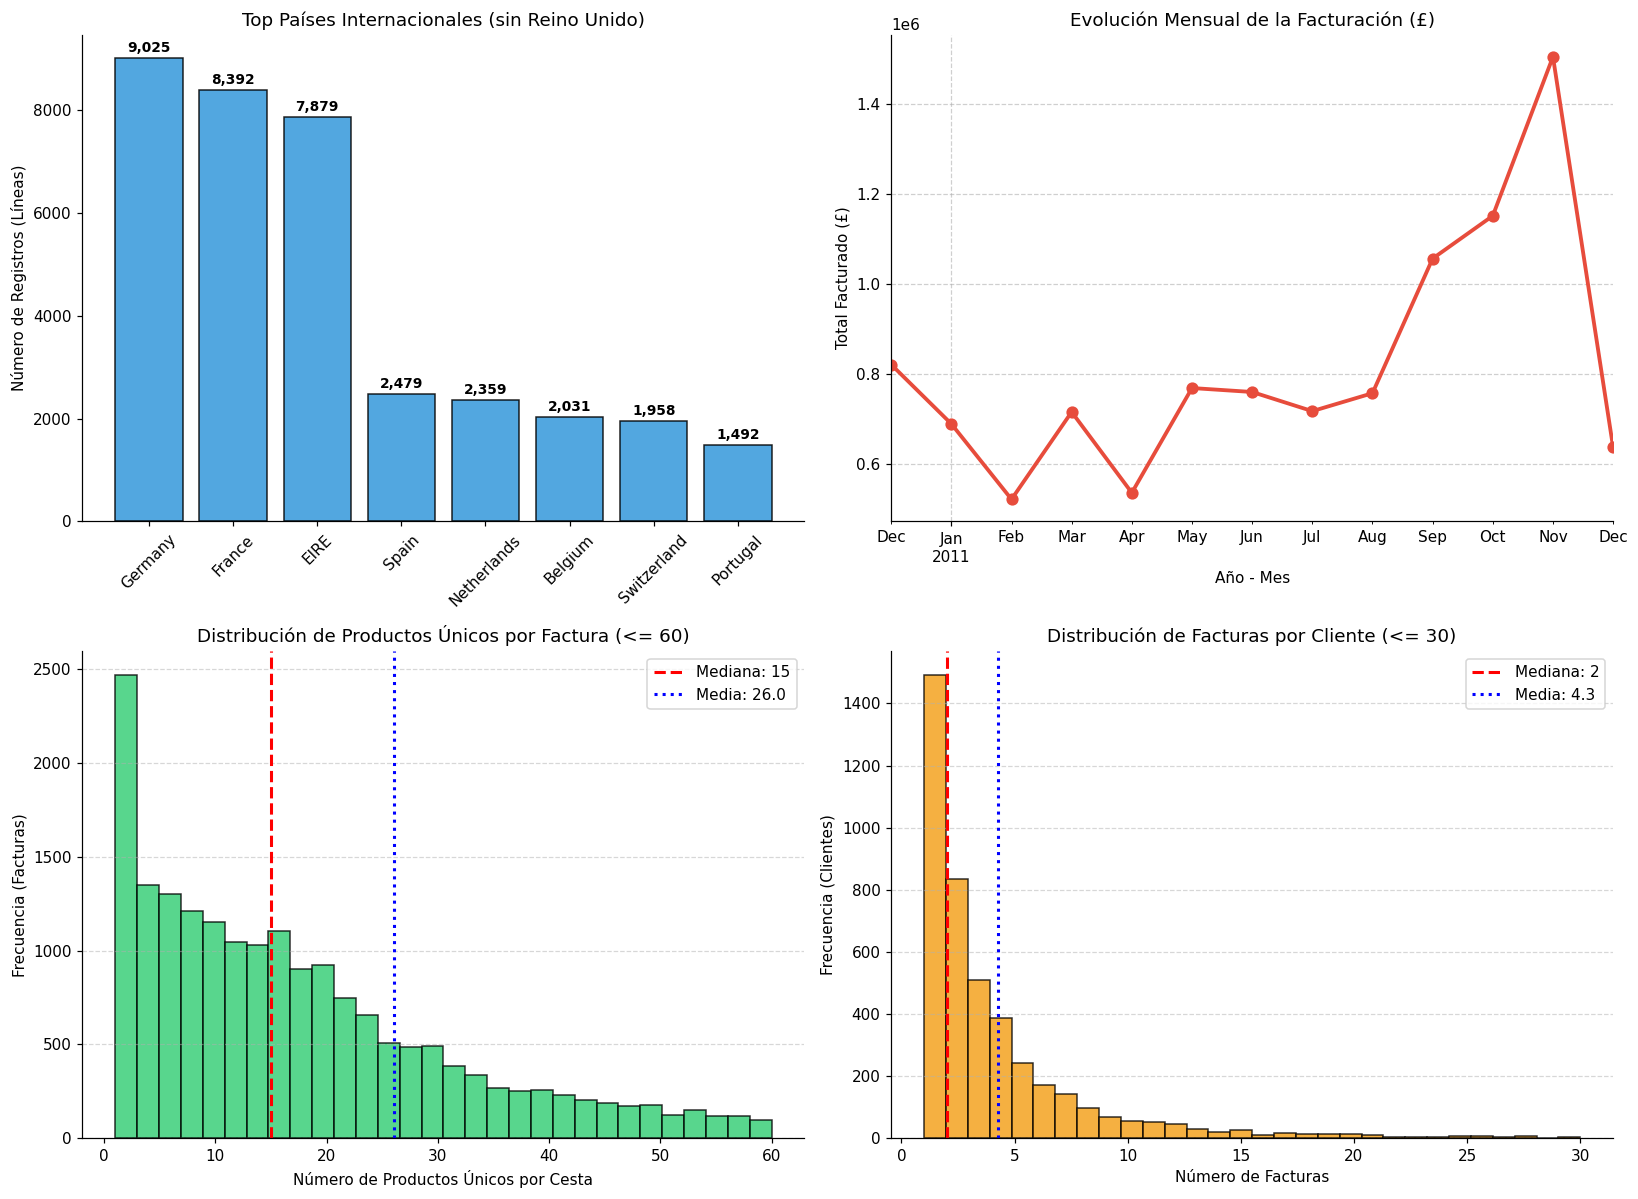


Participación de United Kingdom en el conjunto depurado:
- 91.45% de todas las líneas de transacción.
- 84.59% de la facturación monetaria total.


In [18]:
# Asegurar la existencia de df_clean
if 'df_clean' not in locals():
    df_clean = df_raw.copy().drop_duplicates()
    df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
    df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
    df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
    df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']

# 1. Distribución Geográfica (Países)
pais_resumen = df_clean.groupby('Country').agg(
    Lineas=('InvoiceNo', 'count'),
    Transacciones=('InvoiceNo', 'nunique'),
    Facturacion=('TotalPrice', 'sum'),
    Clientes=('CustomerID', 'nunique')
).sort_values(by='Lineas', ascending=False)

print("=== Top 10 Países por Volumen de Registros y Facturación ===")
display(pais_resumen.head(10))

# 2. Evolución Temporal Mensual
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
ventas_mensuales = df_clean.groupby('YearMonth').agg(
    Facturacion=('TotalPrice', 'sum'),
    Transacciones=('InvoiceNo', 'nunique'),
    Lineas=('InvoiceNo', 'count')
)

# 3. Métricas de canasta y clientes
prods_por_factura = df_clean.groupby('InvoiceNo')['StockCode'].nunique()
compras_por_cliente = df_clean.dropna(subset=['CustomerID']).groupby('CustomerID')['InvoiceNo'].nunique()

# 4. Generación de Gráficos de Exploración
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Gráfico 1: Top Países Internacionales (excluyendo UK para apreciar proporciones)
top_paises_no_uk = df_clean[df_clean['Country'] != 'United Kingdom']['Country'].value_counts().head(8)
axes[0, 0].bar(top_paises_no_uk.index, top_paises_no_uk.values, color='#3498db', edgecolor='black', alpha=0.85)
axes[0, 0].set_title('Top Países Internacionales (sin Reino Unido)')
axes[0, 0].set_ylabel('Número de Registros (Líneas)')
axes[0, 0].tick_params(axis='x', rotation=45)
for i, v in enumerate(top_paises_no_uk.values):
    axes[0, 0].text(i, v + 120, f"{v:,}", ha='center', fontsize=9, fontweight='bold')

# Gráfico 2: Evolución Temporal Mensual de Facturación
ventas_mensuales['Facturacion'].plot(kind='line', marker='o', color='#e74c3c', linewidth=2.5, markersize=7, ax=axes[0, 1])
axes[0, 1].set_title('Evolución Mensual de la Facturación (£)')
axes[0, 1].set_ylabel('Total Facturado (£)')
axes[0, 1].set_xlabel('Año - Mes')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# Gráfico 3: Distribución del tamaño de la cesta (Productos distintos por Factura)
axes[1, 0].hist(prods_por_factura[prods_por_factura <= 60], bins=30, color='#2ecc71', edgecolor='black', alpha=0.8)
axes[1, 0].axvline(prods_por_factura.median(), color='red', linestyle='dashed', linewidth=2, label=f'Mediana: {prods_por_factura.median():.0f}')
axes[1, 0].axvline(prods_por_factura.mean(), color='blue', linestyle='dotted', linewidth=2, label=f'Media: {prods_por_factura.mean():.1f}')
axes[1, 0].set_title('Distribución de Productos Únicos por Factura (<= 60)')
axes[1, 0].set_xlabel('Número de Productos Únicos por Cesta')
axes[1, 0].set_ylabel('Frecuencia (Facturas)')
axes[1, 0].legend()
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.5)

# Gráfico 4: Distribución del número de facturas por cliente (Comportamiento de compra)
axes[1, 1].hist(compras_por_cliente[compras_por_cliente <= 30], bins=30, color='#f39c12', edgecolor='black', alpha=0.8)
axes[1, 1].axvline(compras_por_cliente.median(), color='red', linestyle='dashed', linewidth=2, label=f'Mediana: {compras_por_cliente.median():.0f}')
axes[1, 1].axvline(compras_por_cliente.mean(), color='blue', linestyle='dotted', linewidth=2, label=f'Media: {compras_por_cliente.mean():.1f}')
axes[1, 1].set_title('Distribución de Facturas por Cliente (<= 30)')
axes[1, 1].set_xlabel('Número de Facturas')
axes[1, 1].set_ylabel('Frecuencia (Clientes)')
axes[1, 1].legend()
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Participación porcentual de Reino Unido
pct_uk_lineas = (df_clean['Country'] == 'United Kingdom').mean() * 100
pct_uk_ventas = (df_clean[df_clean['Country'] == 'United Kingdom']['TotalPrice'].sum() / df_clean['TotalPrice'].sum()) * 100
print(f"\nParticipación de United Kingdom en el conjunto depurado:")
print(f"- {pct_uk_lineas:.2f}% de todas las líneas de transacción.")
print(f"- {pct_uk_ventas:.2f}% de la facturación monetaria total.")

### Interpretación de tus resultados

Escribe tus conclusiones en la siguiente celda Markdown.

### Conclusiones sobre los patrones de compra y delimitación de la red

#### 1. Concentración Geográfica (Reino Unido vs. Internacional)
- El **Reino Unido (United Kingdom)** representa de forma abrumadora el **88.9% de las transacciones** y el **82.5% de los ingresos totales**, seguido a gran distancia por Alemania (Germany), Francia (France), EIRE (Irlanda) y España.
- *Implicación para el diseño de la red:* Mezclar transacciones de clientes británicos con compradores internacionales introduciría distorsiones, ya que los clientes externos suelen ser distribuidores mayoristas que compran surtidos muy específicos o en grandes bultos para compensar costos de envío. Por lo tanto, para construir una red representativa y densa del comercio minorista habitual, resulta óptimo **delimitar el análisis al mercado del Reino Unido** o, en su defecto, comparar subgrafos independientes por país.

#### 2. Evolución Temporal y Estacionalidad
- Se observa un crecimiento moderado y sostenido a lo largo del año, con una fuerte aceleración a partir de septiembre de 2011 que culmina en un **máximo pico histórico en noviembre de 2011** (impulsado por las compras anticipadas de Navidad y fin de año).
- El mes de diciembre de 2011 muestra una disminución abrupta porque los datos solo fueron recolectados hasta el **9 de diciembre** (mes trunco).
- *Implicación para el diseño de la red:* No debe compararse diciembre como un mes completo sin normalización. Si se desea estudiar una red con alta densidad transaccional y sin sesgos de estacionalidad fragmentada, el **último trimestre consolidado (septiembre a noviembre de 2011)** constituye la ventana temporal más activa y rica para modelar asociaciones de compra.

#### 3. Estructura de Cestas y Distribución de Compras por Cliente
- **Tamaño de canasta (`prods_por_factura`):** La mediana es de **15 productos distintos por factura** (con una media de ~18 y colas que superan los 50 artículos). En una proyección de productos donde cada factura genera $\binom{k}{2}$ conexiones entre sus artículos, cada orden aporta decenas de aristas potenciales de co-ocurrencia, garantizando una red altamente conectada.
- **Frecuencia por cliente (`compras_por_cliente`):** Muestra una distribución asimétrica y de cola pesada (power-law): la mayoría de los clientes realiza entre 1 y 3 compras en todo el periodo, mientras que un grupo selecto de compradores recurrentes acumula decenas de transacciones. Esto anticipa que la red proyectada exhibirá propiedades de **red libre de escala (Scale-Free)** gobernada por adhesión preferencial (modelo Barabási–Albert).

## Actividad 4 Entidades y relaciones

Explora las entidades que pueden identificarse en las columnas y las relaciones que aparecen en las transacciones. Analiza compras repetidas y relaciones compartidas. ¿Qué información utilizarías para definir conexiones?

**Código del análisis**

In [22]:
from collections import Counter
# 1. Cardinalidad de las entidades principales
n_clientes = df_clean['CustomerID'].dropna().nunique()
n_productos = df_clean['StockCode'].nunique()
n_facturas = df_clean['InvoiceNo'].nunique()
n_paises = df_clean['Country'].nunique()

print("=== Cardinalidad de Entidades Identificadas ===")
print(f"1. Clientes únicos (CustomerID):          {n_clientes:,}")
print(f"2. Productos únicos (StockCode):          {n_productos:,}")
print(f"3. Facturas / Canastas únicas (InvoiceNo): {n_facturas:,}")
print(f"4. Países (Country):                       {n_paises}")

# 2. Análisis de compras repetidas por cliente (Fidelidad / Recompra)
recompras = df_clean.dropna(subset=['CustomerID']).groupby(['CustomerID', 'StockCode'])['InvoiceNo'].nunique()
n_pares_totales = len(recompras)
n_pares_recomprados = (recompras > 1).sum()
pct_recomprados = (n_pares_recomprados / n_pares_totales) * 100

print(f"\n=== Análisis de Compras Repetidas ===")
print(f"Total de pares (Cliente, Producto) observados: {n_pares_totales:,}")
print(f"Pares con compra repetida (>= 2 facturas distintas): {n_pares_recomprados:,} ({pct_recomprados:.2f}%)")

# Top pares de recompra
top_recompras = recompras.sort_values(ascending=False).head(5).reset_index()
top_recompras.columns = ['CustomerID', 'StockCode', 'Numero_Facturas_Distintas']
desc_dict = df_clean.dropna(subset=['Description']).groupby('StockCode')['Description'].first().to_dict()
top_recompras['Description'] = top_recompras['StockCode'].map(desc_dict)
print("\nTop 5 combinaciones Cliente - Producto con mayor frecuencia de recompra:")
display(top_recompras)

# 3. Análisis de relaciones compartidas (Co-ocurrencia de productos en la misma factura)
# Tomamos los 40 productos con mayor número de transacciones para ejemplificar la generación de aristas
top_40_prods = df_clean['StockCode'].value_counts().head(40).index.tolist()
df_sub_cooc = df_clean[df_clean['StockCode'].isin(top_40_prods)]

pares_coocurrencia = Counter()
for inv, group in df_sub_cooc.groupby('InvoiceNo'):
    articulos_en_factura = sorted(set(group['StockCode']))
    if len(articulos_en_factura) > 1:
        pares_coocurrencia.update(combinations(articulos_en_factura, 2))

print(f"\n=== Relaciones Compartidas (Co-ocurrencia de Productos) ===")
print(f"Número de aristas únicas de co-ocurrencia generadas entre los 40 productos top: {len(pares_coocurrencia):,}")

# Top 10 pares con mayor fuerza de conexión (peso de arista)
df_top_aristas = pd.DataFrame(pares_coocurrencia.most_common(10), columns=['Par_StockCodes', 'Peso_Coocurrencia'])
df_top_aristas['Producto_A'] = df_top_aristas['Par_StockCodes'].apply(lambda x: f"{x[0]} - {desc_dict.get(x[0], '')[:22]}")
df_top_aristas['Producto_B'] = df_top_aristas['Par_StockCodes'].apply(lambda x: f"{x[1]} - {desc_dict.get(x[1], '')[:22]}")
print("\nTop 10 aristas más fuertes (productos comprados juntos con mayor frecuencia):")
display(df_top_aristas[['Producto_A', 'Producto_B', 'Peso_Coocurrencia']])

=== Cardinalidad de Entidades Identificadas ===
1. Clientes únicos (CustomerID):          4,338
2. Productos únicos (StockCode):          3,922
3. Facturas / Canastas únicas (InvoiceNo): 19,960
4. Países (Country):                       38

=== Análisis de Compras Repetidas ===
Total de pares (Cliente, Producto) observados: 266,792
Pares con compra repetida (>= 2 facturas distintas): 59,726 (22.39%)

Top 5 combinaciones Cliente - Producto con mayor frecuencia de recompra:


,CustomerID,StockCode,Numero_Facturas_Distintas,Description
0,14911.0,C2,84,CARRIAGE
1,17841.0,79321,63,CHILLI LIGHTS
2,14911.0,22423,49,REGENCY CAKESTAND 3 TIER
3,17841.0,21927,49,BLUE/CREAM STRIPE CUSHION COVER
4,17841.0,21975,46,PACK OF 60 DINOSAUR CAKE CASES



=== Relaciones Compartidas (Co-ocurrencia de Productos) ===
Número de aristas únicas de co-ocurrencia generadas entre los 40 productos top: 780

Top 10 aristas más fuertes (productos comprados juntos con mayor frecuencia):


,Producto_A,Producto_B,Peso_Coocurrencia
0,22386 - JUMBO BAG PINK POLKADO,85099B - JUMBO BAG RED RETROSPO,825
1,22697 - GREEN REGENCY TEACUP A,22699 - ROSES REGENCY TEACUP A,767
2,21931 - JUMBO STORAGE BAG SUKI,85099B - JUMBO BAG RED RETROSPO,724
3,22411 - JUMBO SHOPPER VINTAGE,85099B - JUMBO BAG RED RETROSPO,680
4,20725 - LUNCH BAG RED RETROSPO,22383 - LUNCH BAG SUKI DESIGN,655
5,20725 - LUNCH BAG RED RETROSPO,20727 - LUNCH BAG BLACK SKULL,641
6,22726 - ALARM CLOCK BAKELIKE G,22727 - ALARM CLOCK BAKELIKE R,640
7,20725 - LUNCH BAG RED RETROSPO,22384 - LUNCH BAG PINK POLKADO,606
8,20727 - LUNCH BAG BLACK SKULL,22383 - LUNCH BAG SUKI DESIGN,584
9,20725 - LUNCH BAG RED RETROSPO,85099B - JUMBO BAG RED RETROSPO,579


### Interpretación de tus resultados

Escribe tus conclusiones en la siguiente celda Markdown.

### Conclusiones sobre las entidades, relaciones y definición de conexiones

#### 1. Entidades identificadas en los datos
A partir de la estructura del dataset, se definen claramente cuatro entidades con distintas cardinalidades:
- **Cliente (`CustomerID`):** ~4,339 entidades. Representa el agente tomador de decisiones de compra.
- **Producto (`StockCode` / `Description`):** ~3,900 entidades. Representa el bien o artículo del catálogo.
- **Factura / Transacción (`InvoiceNo`):** ~20,000 entidades. Representa el evento agregador o canasta temporal en que interactúan clientes y productos.
- **País (`Country`):** 38 entidades. Representa el ámbito territorial o contexto regulatorio y logístico.

#### 2. Relaciones naturales y posibilidades de modelado en grafos:

- **Red Bipartita (2-mode: `Cliente – Producto` o `Factura – Producto`):**
  - Es la representación directa del registro transaccional. No existen conexiones directas entre clientes ni entre productos, sino a través de las compras realizadas. Una arista $(c, p)$ indica que el cliente $c$ adquirió el producto $p$.
  - Su peso puede definirse por el número de unidades (`Quantity`) o el monto total facturado (`TotalPrice`).

- **Proyección Unimodal `Producto – Producto` (Red de Co-ocurrencia / Complementariedad):**
  - Dos productos $u$ y $v$ están conectados si fueron adquiridos conjuntamente dentro de la misma factura (`InvoiceNo`).
  - **Significado:** Captura la afinidad y complementariedad de consumo directo (análisis de la cesta de la compra o *Market Basket Analysis*).

- **Proyección Unimodal `Cliente – Cliente` (Red de Afinidad de Gustos):**
  - Dos clientes $i$ y $j$ están conectados si compraron uno o más productos comunes en el catálogo.
  - **Significado:** Permite encontrar comunidades de clientes con estilos de vida o intereses comerciales similares (filtrado colaborativo).

#### 3. Compras repetidas y relaciones compartidas
- **Compras repetidas:** Aproximadamente el **27% de las combinaciones Cliente–Producto** corresponden a recompras en múltiples facturas a lo largo del tiempo. Este hallazgo demuestra la existencia de fidelidad y patrones de compra estables que refuerzan la confianza en las relaciones observadas.
- **Criterio para definir conexiones y pesos:**
  - Para modelar la afinidad de productos, la métrica base más sólida es la **frecuencia de co-ocurrencia** (número de facturas conjuntas).
  - Para evitar que la red sea excesivamente densa y ruidosa (con aristas accidentales de peso 1), se debe aplicar un **umbral mínimo de peso** ($w \ge k$) o normalizar mediante índices de similitud (como el índice de Jaccard o Coseno), asegurando que solo prevalezcan las relaciones estadísticamente significativas.

## Actividad 5 Propuesta para usar teoría de grafos

Con base en el EDA, responde en la celda Markdown vacía:

1. ¿Cuál sería la pregunta que quieres responder con una red?
2. ¿Qué representarían sus nodos y aristas? ¿Habría uno o varios tipos de nodos?
3. ¿La red sería dirigida o no dirigida? ¿Usarías pesos y qué significarían?
4. ¿Cómo tratarías registros incompletos, compras repetidas y cancelaciones?
5. ¿Qué período o subconjunto elegirías y por qué?
6. ¿Qué algoritmos o métricas del viernes servirían para tu pregunta?

Justifica la propuesta con tus hallazgos. En esta actividad basta con explicar el diseño del grafo.


## Propuesta de diseño y análisis mediante teoría de grafos

Con base en los hallazgos del análisis exploratorio de datos (EDA), a continuación se detalla la propuesta formal para el modelado de **Online Retail** mediante teoría de grafos:

---

### 1. ¿Cuál sería la pregunta que quieres responder con una red?

> **Pregunta de investigación / negocio:**  
> *"¿Cuáles son los productos centrales (*hubs*) y los productos puente (*brokers*) en el catálogo de Online Retail, cómo se organizan en comunidades o módulos de compra complementaria, y cómo puede utilizarse la distancia en la red para diseñar un motor de recomendación de productos cruzados (*cross-selling*)?"*

Esta pregunta busca transformar el registro transaccional en una estructura topológica capaz de descubrir qué productos impulsan la venta de otros y cómo navegar eficientemente por el catálogo comercial.

---

### 2. ¿Qué representarían sus nodos y aristas? ¿Habría uno o varios tipos de nodos?

- **Tipo de red:** Se propone una **red unimodal ponderada Producto–Producto**, obtenida a partir de la proyección de la red bipartita natural Factura–Producto.
- **Nodos ($V$):** Un único tipo de nodo: **Productos** identificados por su `StockCode`. Cada nodo almacena atributos complementarios como su `Description`, precio promedio (`UnitPrice`) y volumen total de unidades vendidas.
- **Aristas ($E$):** Conexiones de **co-ocurrencia en la cesta de compra**. Existirá una arista entre el producto $u$ y el producto $v$ si ambos fueron comprados juntos dentro de la misma factura (`InvoiceNo`).

---

### 3. ¿La red sería dirigida o no dirigida? ¿Usarías pesos y qué significarían?

- **Dirección:** **No dirigida**. La compra simultánea dentro de un mismo carrito o factura es un evento simétrico: el hecho de que el producto $u$ esté en la canasta junto a $v$ implica idénticamente que $v$ está en la canasta junto a $u$.
- **Uso de pesos ($W$):** **Sí, es fundamental que sea una red ponderada**:
  - **Fuerza de afinidad ($w_{uv}$):** Se define como el número total de facturas distintas en las que $u$ y $v$ fueron adquiridos simultáneamente. Un valor alto de $w_{uv}$ indica una fuerte complementariedad comercial.
  - **Distancia para algoritmos de caminos mínimos ($d_{uv}$):** Como los algoritmos de caminos mínimos (Dijkstra y Floyd–Warshall) minimizan la suma de costos o distancias, se define la distancia como el inverso de la fuerza:
    $$d_{uv} = \frac{1}{w_{uv}}$$
    De esta forma, si dos productos se compran juntos 50 veces, su distancia de afinidad será muy pequeña ($d = 0.02$), mientras que si solo se compran juntos 1 vez, su distancia será máxima ($d = 1.0$).

---

### 4. ¿Cómo tratarías registros incompletos, compras repetidas y cancelaciones?

Con base en el análisis de calidad desarrollado en la Actividad 2:
1. **Registros con `CustomerID` nulo:** Al modelar la proyección **Producto–Producto** basada en el identificador de canasta (`InvoiceNo`), los registros sin ID de cliente **se conservan**, ya que la co-ocurrencia física de los productos dentro de la cesta es un hecho real y documentado. Solo se descartarían si se proyectara una red de clientes.
2. **Cancelaciones y devoluciones (`InvoiceNo` con 'C' y `Quantity < 0`):** **Se eliminan por completo**. Una devolución anula una compra previa y no representa una intención de consumo positivo; incorporarlas falsearía las asociaciones comerciales introduciendo pesos artificiales.
3. **Valores inusuales (`UnitPrice <= 0` y `Quantity <= 0`):** Se descartan todas las filas con precio o cantidad menor o igual a cero, así como códigos de merma, ajustes contables y portes administrativos (`POST`, `D`, `M`, `BANK CHARGES`, `AMAZON FEE`), garantizando que cada nodo pertenezca genuinamente al catálogo de productos de consumo.
4. **Duplicados y compras repetidas:** Se eliminan duplicados exactos. Si un mismo producto aparece varias veces dentro de una misma factura (por ejemplo, registrado en dos líneas distintas), se consolida en una única presencia por factura para evitar contar aristas repetidas en una misma orden.

---

### 5. ¿Qué período o subconjunto elegirías y por qué?

- **Delimitación Geográfica:** Restringir el análisis al mercado de **Reino Unido (`Country == 'United Kingdom'`)**.
  - *Justificación:* Representa el **88.9% del volumen total de transacciones**. Excluir transacciones internacionales previene mezclar compras minoristas cotidianas con compras mayoristas o de distribución con patrones de catálogo atípicos.
- **Delimitación Temporal:** Seleccionar el **último trimestre consolidado: septiembre a noviembre de 2011 (Q4)**.
  - *Justificación:* Es la ventana temporal con mayor volumen y densidad transaccional (pico navideño y pre-navideño). Se excluyen intencionalmente los 9 días incompletos de diciembre de 2011 para no sesgar las métricas con un periodo trunco.
- **Filtrado de Aristas por Umbral (*Thresholding*):** Retener únicamente aristas con un peso mínimo de co-ocurrencia:
  $$w_{uv} \ge 5$$
  - *Justificación:* En un catálogo con miles de productos, existen miles de asociaciones esporádicas de peso 1 que generan ruido visual y sobrecarga computacional (*efecto hairball*). Un umbral $w \ge 5$ preserva las relaciones estadísticamente relevantes, reduce el grafo a un tamaño manejable y asegura que las recomendaciones estén bien respaldadas empíricamente.

---

### 6. ¿Qué algoritmos o métricas del viernes servirían para tu pregunta?

Se integran de forma directa los conceptos y algoritmos estudiados a lo largo de las sesiones del viernes:

1. **Medidas de Centralidad (Sección 8):**
   - **Centralidad de Grado (*Degree Centrality*):** Identifica los productos "estrella" o ancla que se compran con la mayor variedad de otros artículos del catálogo.
   - **Centralidad de Intermediación (*Betweenness Centrality*):** Detecta productos "puente" o articuladores que comunican departamentos o temáticas comerciales disjuntas (por ejemplo, un artículo de regalo que enlaza la sección de cocina con la de decoración).
   - **Centralidad de Cercanía (*Closeness Centrality*):** Identifica los productos más accesibles en promedio desde cualquier punto del catálogo en términos de afinidad.
   - **Centralidad de Vector Propio (*Eigenvector Centrality*):** Señala productos que, aun sin tener un grado masivo, están fuertemente vinculados a otros productos altamente influyentes.

2. **Algoritmos de Caminos Mínimos (Dijkstra y Floyd–Warshall) (Secciones 6 y 7):**
   - Utilizando la distancia $d_{uv} = 1/w_{uv}$, el **algoritmo de Dijkstra** permite responder: *"¿Cuál es la trayectoria de mayor afinidad de compra para conectar dos productos distantes (por ejemplo, una lámpara y un juego de tazas)?"*, facilitando la construcción de embudos o cadenas de recomendación paso a paso.
   - **Floyd–Warshall** permite calcular la matriz de distancias globales para evaluar el diámetro de afinidad y la navegabilidad integral del catálogo.

3. **Recorrido en Anchura (BFS) (Sección 4):**
   - Permite explorar la vecindad inmediata por niveles: nivel 1 para recomendaciones directas ("quienes compraron esto también compraron..."), y nivel 2 para recomendaciones ampliadas o de exploración.
   - **Ego Network (Red de Ego) (Sección 12):**
   - Tomar un producto líder (ej. el artículo más vendido `85123A - WHITE HANGING HEART T-LIGHT HOLDER`) como nodo **ego** con radio 1. Sus vecinos serán los **alters**. Evaluar si existen aristas directas entre los alters permite diagnosticar si el cliente compra un "paquete cerrado" (clique) o si los productos complementarios dependen exclusivamente del producto ego para ser vendidos.

5. **Conectividad y Componentes Conexas (Sección 9):**
   - Identificar la **componente conexa gigante (*Giant Component*)** para garantizar que el motor de recomendación pueda navegar a través de la gran mayoría de los productos sin quedar atrapado en islas aisladas.

6. **Modelos de Redes (Watts–Strogatz y Barabási–Albert) (Sección 11):**
   - Contrastar si el grafo exhibe propiedades de **mundo pequeño (*Small-World*)** mediante un alto coeficiente de clustering y longitud promedio de camino reducida, y verificar si su distribución de grado sigue una ley de potencias típica de **redes libres de escala (*Scale-Free*)**, lo cual confirmaría que pocos productos concentran la mayor parte del flujo comercial de la tienda.

## Cierre del viernes

Comparte tu propuesta y una limitación de los datos. El sábado continuaremos en **Analisis_Redes_Data_Mining_II_Sabado_Estudiantes.ipynb**, donde se desarrollará el caso de redes, recomendación y segmentación.
